# EDA: 2020 COVID-19 Crash

**Owner:** Grace · **Week 1** · Market Stress Early-Warning System

**Goal:** understand what U.S. equity market stress looked like in 2020 at the stock level, check data quality and survivorship for this period, and test whether co-movement among S&P 500 stocks rose *before* the worst of the stress or only during it (Section 7). 2020 is our test of a **sudden outside shock**: if no measure moved before late February, that is a real finding, not a failure.

**Before running:** this notebook reads `data/processed/` (daily, point-in-time S&P 500 member prices). Either run `python scripts/download_sp500_prices.py` from the repo root, or copy the team's shared `data/processed/` folder into the repo. If `data/processed/daily_panel.parquet` from `01_data_collection.ipynb` exists, VIX and the St. Louis Fed Financial Stress Index are added.

**Window:** 2020-01-01 to 2020-12-31, with 2019 loaded as warm-up for rolling windows and as the calm baseline.

**What changed from the first draft:** the first draft used Brandon's *weekly* `^GSPC` file, which cannot show stock-level coverage, dispersion, breadth or connectedness, and labels each week by its *start* date (so "March 16" was really the close of the week starting March 16). This version uses daily member prices and follows the 2008 and 2011 notebooks so the four periods can be compared. The first draft's findings are kept below Section 9.

**Reference dates.** The market peak and trough are computed from the data in Section 3, not typed in. The event dates below are from memory and **must be checked against a primary source before they go in the report**:

| Date | Event | To verify with |
|---|---|---|
| 2020-03-09 | First of several market-wide trading halts (circuit breaker) in March | NYSE or SEC announcement |
| 2020-03-11 | WHO describes COVID-19 as a pandemic | WHO statement |
| 2020-03-15 | Federal Reserve cuts rates to near zero (Sunday; first trading reaction 2020-03-16) | Federal Reserve press release |
| 2020-03-27 | CARES Act signed | Congress.gov |

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import prices as px

PROC = ROOT / "data" / "processed"
if not (PROC / "sp500_close.parquet").exists():
    raise FileNotFoundError(
        f"{PROC / 'sp500_close.parquet'} not found. From the repo root run "
        "`python scripts/download_sp500_prices.py`, or copy the team's shared data/processed/ folder into the repo."
    )

YEAR = 2020
WARMUP, START, END = "2019-01-01", "2020-01-01", "2020-12-31"
CALM, CALM_LABEL = ("2019-01-01", "2019-12-31"), "2019"   # calm comparison period
ACUTE = ("2020-02-20", "2020-04-30")                       # used for the coverage check

# Verify each date against a primary source before citing it (see the table above)
EVENTS = {
    "2020-03-09": "First market-wide halt",
    "2020-03-11": "WHO: pandemic",
    "2020-03-16": "First trading day after Fed cut",
    "2020-03-27": "CARES Act",
}

# Sub-periods for the connectedness table
PERIODS = {
    "Jan to mid-Feb 2020 (before)": ("2020-01-01", "2020-02-19"),
    "late Feb to Mar 2020 (crash)": ("2020-02-20", "2020-03-31"),
    "Apr to Jun 2020 (rebound)": ("2020-04-01", "2020-06-30"),
    "Jul to Dec 2020 (after)": ("2020-07-01", "2020-12-31"),
}

# Baselines for the timing table: (baseline period, search window)
BASELINES = {
    "A: 2019": (slice("2019-01-01", "2019-12-31"), slice(START, END)),
    "B: Jul-Dec 2019": (slice("2019-07-01", "2019-12-31"), slice(START, END)),
}

# Stress episodes from the team's label rule (docs/stress_label_rule.md), shaded on the market charts
episodes = pd.read_csv(ROOT / "docs" / "stress_periods.csv", parse_dates=["start", "end"])
episodes = episodes[(episodes["end"] >= START) & (episodes["start"] <= END)]

def mark_events(ax, labels=True):
    for d, lab in EVENTS.items():
        ax.axvline(pd.Timestamp(d), color="grey", ls="--", lw=0.8)
        if labels:
            ax.text(pd.Timestamp(d), 1.0, f" {lab}", transform=ax.get_xaxis_transform(),
                    rotation=90, va="top", ha="left", fontsize=7, color="grey")

def shade_episodes(ax):
    for _, ep in episodes.iterrows():
        ax.axvspan(max(ep["start"], pd.Timestamp(START)), min(ep["end"], pd.Timestamp(END)),
                   color="tab:red", alpha=0.08, lw=0)

pd.set_option("display.width", 140)
print("Stress episodes in this window:")
display(episodes[["episode_id", "start", "start_trailing", "end", "name"]])

Stress episodes in this window:


,episode_id,start,start_trailing,end,name
8,9,2020-02-14,2020-03-02,2020-06-25,COVID-19 crash


## 1. Load data

In [2]:
close = pd.read_parquet(PROC / "sp500_close.parquet").loc[WARMUP:END]
membership = pd.read_parquet(PROC / "sp500_membership.parquet").loc[WARMUP:END]
report = pd.read_csv(PROC / "sp500_coverage_report.csv", index_col="ticker",
                     parse_dates=["first_price", "last_price", "first_member_day"])

# Daily simple returns from unmasked prices, then keep member days only.
stock_cols = membership.columns
rets_all = close.reindex(columns=stock_cols).pct_change(fill_method=None)
rets = rets_all.where(membership)

gspc = close["^GSPC"]
print(f"{close.index.min().date()} to {close.index.max().date()}: {len(close)} trading days")
print(f"{len(stock_cols)} tickers were members at some point in the full download period")

2019-01-02 to 2020-12-31: 505 trading days
977 tickers were members at some point in the full download period


## 2. Data quality: how much of the index do we actually see?

Survivorship check: on each day, what share of the stocks that were *in the index that day* have a Yahoo price?

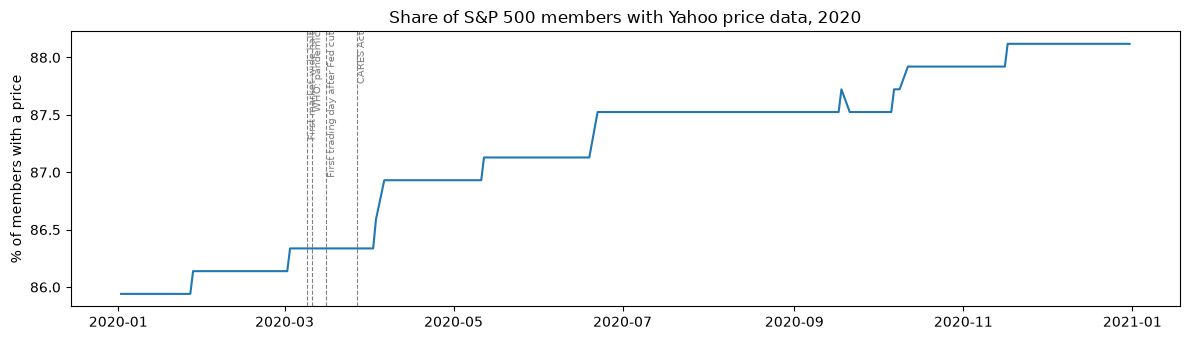

Average share priced, full window: 87.2%
Average share priced, 2020-02-20 to 2020-04-30: 86.5%
Lowest daily share: 85.9% on 2020-01-02


In [3]:
cov = px.coverage_by_day(close, membership).loc[START:END]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(cov.index, cov["share_priced"] * 100)
ax.set_ylabel("% of members with a price")
ax.set_title(f"Share of S&P 500 members with Yahoo price data, {YEAR}")
mark_events(ax)
plt.tight_layout(); plt.show()

acute = cov.loc[ACUTE[0]:ACUTE[1]]
print(f"Average share priced, full window: {cov['share_priced'].mean():.1%}")
print(f"Average share priced, {ACUTE[0]} to {ACUTE[1]}: {acute['share_priced'].mean():.1%}")
print(f"Lowest daily share: {cov['share_priced'].min():.1%} on {cov['share_priced'].idxmin().date()}")

In [4]:
# Members during the window with no or partial price data, ranked by days in the index during the window
win_mem = membership.loc[START:END]
win_has = close.reindex(columns=stock_cols).loc[START:END].notna() & win_mem
gap = pd.DataFrame({
    "member_days_in_window": win_mem.sum(),
    "priced_days_in_window": win_has.sum(),
})
gap = gap[gap["member_days_in_window"] > 0]
gap["coverage_in_window"] = (gap["priced_days_in_window"] / gap["member_days_in_window"]).round(3)
missing = gap[gap["coverage_in_window"] < 1].sort_values(["member_days_in_window", "coverage_in_window"],
                                                         ascending=[False, True])
info_cols = [c for c in ["first_price", "last_price", "late_start", "check_ticker_reuse", "prices_from"] if c in report]
missing = missing.join(report[info_cols], how="left")
print(f"{len(missing)} of {len(gap)} window members have incomplete prices; "
      f"{int((gap['priced_days_in_window'] == 0).sum())} have none")
missing.head(40)

72 of 525 window members have incomplete prices; 72 have none


,member_days_in_window,priced_days_in_window,coverage_in_window,first_price,last_price,late_start,check_ticker_reuse
ABC,253,0,0.0,NaT,NaT,False,False
ABMD,253,0,0.0,NaT,NaT,False,False
ALXN,253,0,0.0,NaT,NaT,False,False
ANSS,253,0,0.0,NaT,NaT,False,False
ANTM,253,0,0.0,NaT,NaT,False,False
ATVI,253,0,0.0,NaT,NaT,False,False
AVB,253,0,0.0,2026-08-14,2026-08-14,True,False
BK,253,0,0.0,NaT,NaT,False,False
BLL,253,0,0.0,NaT,NaT,False,False
CERN,253,0,0.0,NaT,NaT,False,False


*For the write-up:* look at the names above. Are the missing ones firms that failed or were acquired after this period, or renamed tickers (the `prices_from` column shows renames we already fixed)? Well-known companies that still trade under a new symbol can be added to `TICKER_ALIASES` in `src/universe.py`.

### 2b. Price sanity: implausible daily returns

Member-days with an absolute daily return above 40% are listed and those tickers are excluded from the stock-level measures below. These are usually ticker reuse (a symbol that later belonged to another company). In 2020 some real stocks did move a lot, so look at each one before deciding it is an error.

**Team decision (2026-10-28):** the flagged moves in 2020 are real (OXY, APA and FANG on 2020-03-09 (the oil price crash), NCLH and DXC on 2020-03-24, AAL on 2020-06-04 and BIIB on 2020-11-04), so those stocks are kept in all measures. They are listed in `REAL_MOVES` below; any new flag not on that list is still excluded until checked.

In [5]:
JUMP = 0.40
r_win = rets.loc[START:END]
jumps = r_win.stack()
jumps = jumps[jumps.abs() > JUMP].rename("daily_return").reset_index()
jumps.columns = ["date", "ticker", "daily_return"]
print(jumps.sort_values(["ticker", "date"]).to_string(index=False) if len(jumps) else "No member-day moves above 40%.")

# Team decision (2026-10-28): these flagged moves are real, so the stocks stay in.
# Any NEW flag not on this list is still excluded until someone checks it.
REAL_MOVES = ['AAL', 'APA', 'BIIB', 'DXC', 'FANG', 'NCLH', 'OXY']
print(f"\nReal moves kept in: {sorted(set(jumps['ticker']) & set(REAL_MOVES))}")
BAD_TICKERS = sorted(set(jumps["ticker"]) - set(REAL_MOVES))
print(f"\nExcluded from stock-level measures: {BAD_TICKERS}")
rets = rets.drop(columns=BAD_TICKERS)
stock_cols = stock_cols.drop(BAD_TICKERS)

      date ticker  daily_return
2020-06-04    AAL      0.410970
2020-03-09    APA     -0.538647
2020-11-04   BIIB      0.439739
2020-03-24    DXC      0.410160
2020-03-09   FANG     -0.446458
2020-03-24   NCLH      0.421923
2020-03-09    OXY     -0.520138

Real moves kept in: ['AAL', 'APA', 'BIIB', 'DXC', 'FANG', 'NCLH', 'OXY']

Excluded from stock-level measures: []


## 3. Market overview: level, drawdown and volatility

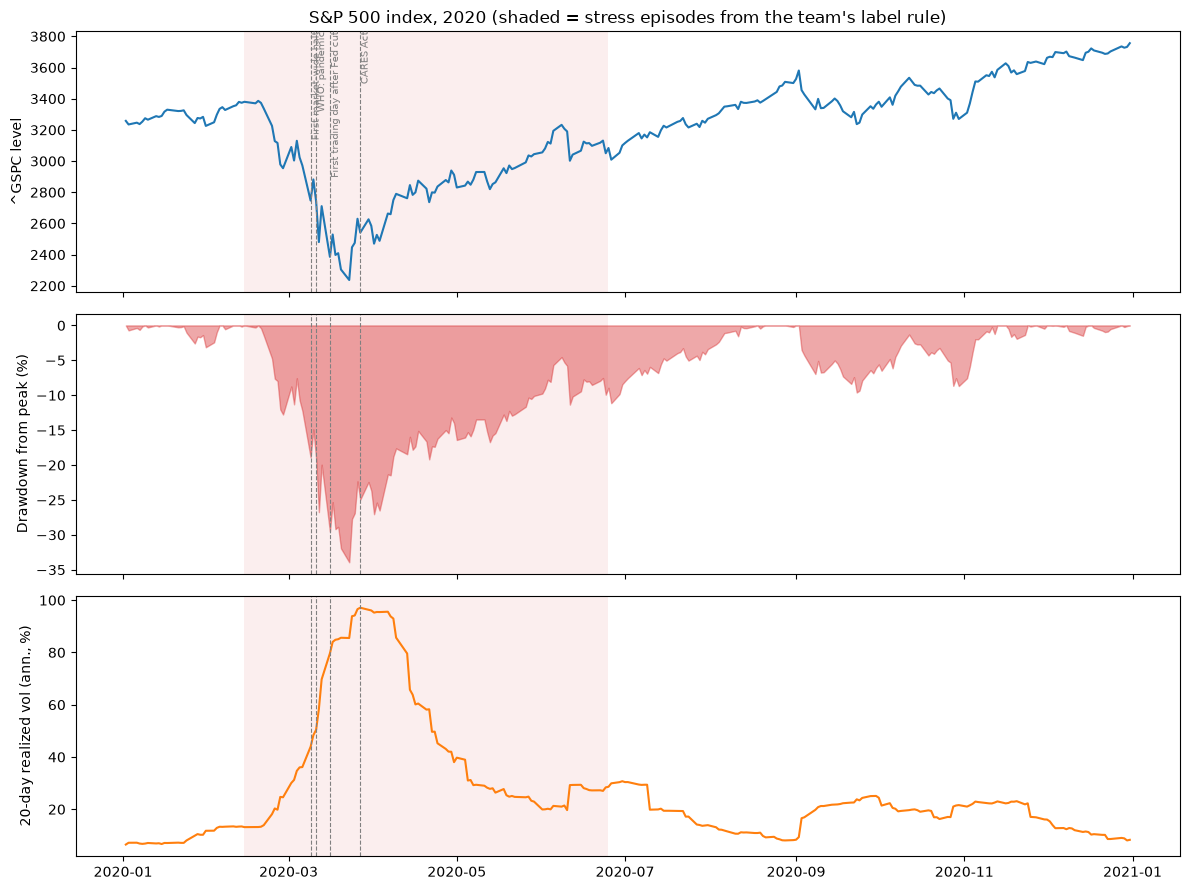

Peak close before the drawdown: 3,386.15 on 2020-02-19
Trough close: 2,237.40 on 2020-03-23
Maximum drawdown: -33.9% over 23 trading days
Highest 20-day realized vol: 97.1% on 2020-03-27
Average 20-day realized vol, 2019: 11.3%


In [6]:
g = gspc.loc[START:END]
drawdown = g / g.cummax() - 1
daily = gspc.pct_change(fill_method=None)
vol20 = daily.rolling(20).std().loc[START:END] * np.sqrt(252)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(g.index, g); axes[0].set_ylabel("^GSPC level")
axes[1].fill_between(drawdown.index, drawdown * 100, 0, color="tab:red", alpha=0.4)
axes[1].set_ylabel("Drawdown from peak (%)")
axes[2].plot(vol20.index, vol20 * 100, color="tab:orange"); axes[2].set_ylabel("20-day realized vol (ann., %)")
for i, ax in enumerate(axes):
    shade_episodes(ax)
    mark_events(ax, labels=(i == 0))
axes[0].set_title(f"S&P 500 index, {YEAR} (shaded = stress episodes from the team's label rule)")
plt.tight_layout(); plt.show()

trough_date = drawdown.idxmin()
peak_date = g.loc[:trough_date].idxmax()
print(f"Peak close before the drawdown: {g[peak_date]:,.2f} on {peak_date.date()}")
print(f"Trough close: {g[trough_date]:,.2f} on {trough_date.date()}")
print(f"Maximum drawdown: {drawdown.min():.1%} over {len(g.loc[peak_date:trough_date]) - 1} trading days")
print(f"Highest 20-day realized vol: {vol20.max():.1%} on {vol20.idxmax().date()}")
print(f"Average 20-day realized vol, {CALM_LABEL}: {(daily.rolling(20).std() * np.sqrt(252)).loc[CALM[0]:CALM[1]].mean():.1%}")

### 3b. Returns and recovery

Carried over from the first (weekly) draft of this notebook, now on daily closes.

In [7]:
g_rets = daily.loc[START:END]
first, last = g.iloc[0], g.iloc[-1]
recovered = g.loc[trough_date:][g.loc[trough_date:] >= g[peak_date]]
vol_prev = daily.loc[CALM[0]:CALM[1]].std() * np.sqrt(252)
vol_year = g_rets.std() * np.sqrt(252)

print(f"First-to-last close in {YEAR}: {first:,.2f} -> {last:,.2f} ({last / first - 1:+.1%}, price index, no dividends)")
print(f"First close back at or above the pre-drawdown peak: "
      f"{recovered.index[0].date() if len(recovered) else 'not within this window'}")
print(f"Annualized daily volatility: {CALM_LABEL} {vol_prev:.1%}, {YEAR} {vol_year:.1%} ({vol_year / vol_prev:.2f}x)")
print(f"$10,000 at the peak close would have fallen to about ${10_000 * (1 + drawdown.min()):,.0f} at the trough "
      "(index level only, no fees or dividends)")
print("\nFive worst and five best daily returns of ^GSPC (%):")
ranked = (g_rets * 100).round(2).sort_values()
display(pd.concat([ranked.head(5), ranked.tail(5)]).to_frame("daily return (%)"))

First-to-last close in 2020: 3,257.85 -> 3,756.07 (+15.3%, price index, no dividends)
First close back at or above the pre-drawdown peak: 2020-08-18
Annualized daily volatility: 2019 12.5%, 2020 34.4% (2.76x)
$10,000 at the peak close would have fallen to about $6,608 at the trough (index level only, no fees or dividends)

Five worst and five best daily returns of ^GSPC (%):


,daily return (%)
Date,
2020-03-16,-11.98
2020-03-12,-9.51
2020-03-09,-7.60
2020-06-11,-5.89
2020-03-18,-5.18
2020-03-17,6.00
2020-03-26,6.24
2020-04-06,7.03
2020-03-13,9.29


### 3c. VIX and the St. Louis Fed Financial Stress Index (optional)

Runs only if `daily_panel.parquet` from `01_data_collection.ipynb` exists. Both series are FRED data. `STLFSI4` is weekly and is forward-filled onto trading days by observation date, which is fine for EDA but **not** for modeling (release lag, see `01_data_collection.ipynb`).

In [8]:
panel_path = PROC / "daily_panel.parquet"
vix = stl = None
if panel_path.exists():
    panel = pd.read_parquet(panel_path)
    if "VIXCLS" in panel:
        vix = panel["VIXCLS"].reindex(close.index).ffill()
    if "STLFSI4" in panel:
        stl = panel["STLFSI4"].ffill().reindex(close.index, method="ffill")

if vix is None and stl is None:
    print("daily_panel.parquet not found; run 01_data_collection.ipynb to add VIX and STLFSI4.")
else:
    fig, ax1 = plt.subplots(figsize=(12, 4))
    if vix is not None:
        v = vix.loc[START:END]
        ax1.plot(v.index, v, color="tab:orange", label="VIX close"); ax1.set_ylabel("VIX")
        print(f"VIX peak close: {v.max():.1f} on {v.idxmax().date()}")
    if stl is not None:
        ax2 = ax1.twinx()
        s = stl.loc[START:END]
        ax2.plot(s.index, s, color="tab:red", label="STLFSI4"); ax2.set_ylabel("STLFSI4", color="tab:red")
        print(f"STLFSI4 peak: {s.max():.2f} on {s.idxmax().date()}")
    shade_episodes(ax1); mark_events(ax1)
    ax1.set_title(f"VIX and St. Louis Fed Financial Stress Index, {YEAR}")
    plt.tight_layout(); plt.show()

daily_panel.parquet not found; run 01_data_collection.ipynb to add VIX and STLFSI4.


## 4. Sanity check: equal-weighted member portfolio vs the index

The official index is cap-weighted, so the two lines should move together but not match. A large, persistent gap would point to a data problem. `^GSPC` is a price index while member returns come from dividend-adjusted closes, so the equal-weighted line should end slightly higher even with identical stocks.

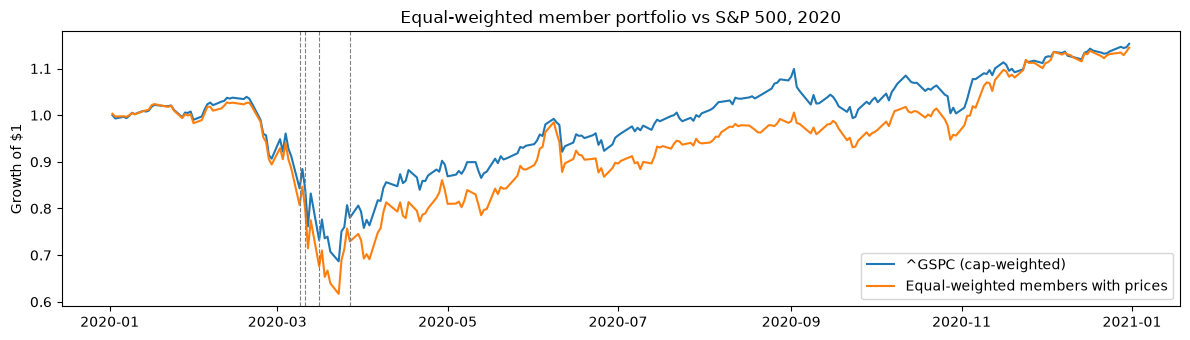

Correlation of daily returns (EW vs ^GSPC): 0.953
2020 total return: EW 14.5%, ^GSPC price index 15.3%


In [9]:
ew = rets.loc[START:END].mean(axis=1, skipna=True)
ew_level = (1 + ew.fillna(0)).cumprod()
ix_level = g / g.iloc[0]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(ix_level.index, ix_level, label="^GSPC (cap-weighted)")
ax.plot(ew_level.index, ew_level, label="Equal-weighted members with prices")
ax.set_ylabel("Growth of $1"); ax.legend(); mark_events(ax, labels=False)
ax.set_title(f"Equal-weighted member portfolio vs S&P 500, {YEAR}")
plt.tight_layout(); plt.show()

daily_corr = ew.corr(g_rets)
print(f"Correlation of daily returns (EW vs ^GSPC): {daily_corr:.3f}")
print(f"{YEAR} total return: EW {ew_level.iloc[-1] - 1:.1%}, ^GSPC price index {ix_level.iloc[-1] - 1:.1%}")

## 5. Cross-section: dispersion and breadth

* **Dispersion:** standard deviation of returns across stocks each day.
* **Breadth:** share of members trading above their own 50-day moving average.

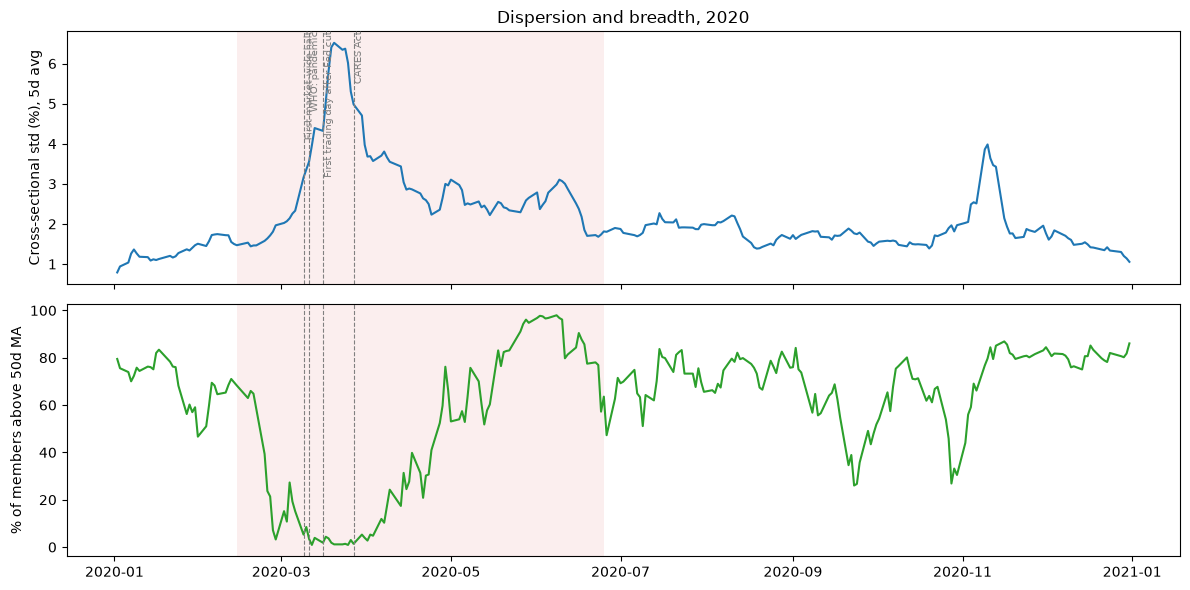

Dispersion (5d avg): 2019 mean 1.39%, peak 6.52% on 2020-03-20
Breadth: 2019 mean 64.4%, low 0.9% on 2020-03-12


In [10]:
dispersion_full = rets.std(axis=1, skipna=True)
disp5_full = dispersion_full.rolling(5).mean()
disp5 = disp5_full.loc[START:END]
ma50 = close.reindex(columns=stock_cols).rolling(50, min_periods=50).mean()
above = (close.reindex(columns=stock_cols) > ma50).where(membership[stock_cols] & ma50.notna())
breadth_full = above.mean(axis=1, skipna=True)
breadth = breadth_full.loc[START:END]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(disp5.index, disp5 * 100)
axes[0].set_ylabel("Cross-sectional std (%), 5d avg")
axes[1].plot(breadth.index, breadth * 100, color="tab:green")
axes[1].set_ylabel("% of members above 50d MA")
for i, ax in enumerate(axes):
    shade_episodes(ax)
    mark_events(ax, labels=(i == 0))
axes[0].set_title(f"Dispersion and breadth, {YEAR}")
plt.tight_layout(); plt.show()

print(f"Dispersion (5d avg): {CALM_LABEL} mean {disp5_full.loc[CALM[0]:CALM[1]].mean():.2%}, "
      f"peak {disp5.max():.2%} on {disp5.idxmax().date()}")
print(f"Breadth: {CALM_LABEL} mean {breadth_full.loc[CALM[0]:CALM[1]].mean():.1%}, "
      f"low {breadth.min():.1%} on {breadth.idxmin().date()}")

## 6. Connectedness: did stocks start moving together before the worst of the stress?

For every 5th trading day, take the previous 60 trading days of returns for stocks that were members with complete data over that window, and compute the **average pairwise correlation** and the **first principal component variance share** (largest eigenvalue / number of stocks). Both measure co-movement *among S&P 500 stocks*, not across asset classes.

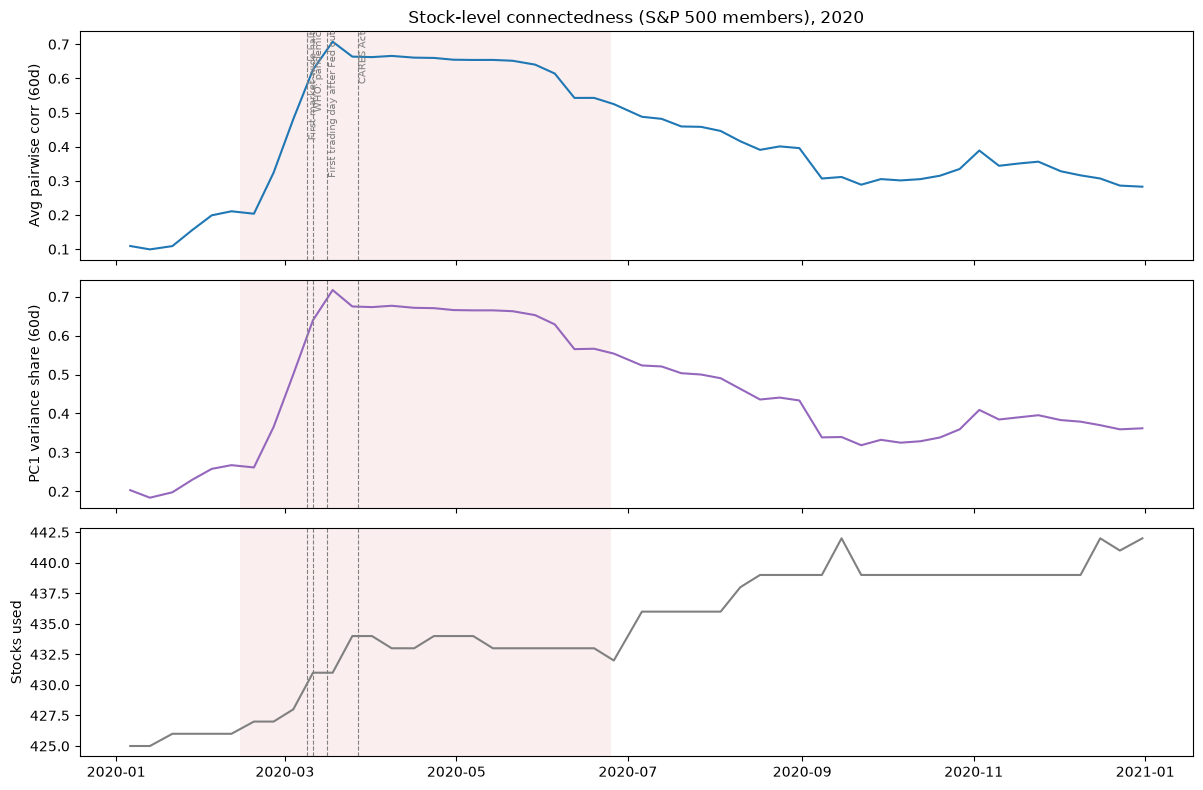

In [11]:
def connectedness(returns: pd.DataFrame, window: int = 60, step: int = 5, min_stocks: int = 100) -> pd.DataFrame:
    rows = {}
    idx = returns.index
    for end in range(window, len(idx) + 1, step):
        block = returns.iloc[end - window:end]
        block = block.loc[:, block.notna().all()]          # complete data over the window only
        block = block.loc[:, block.std() > 0]
        n = block.shape[1]
        if n < min_stocks:
            continue
        c = np.corrcoef(block.values, rowvar=False)
        avg = (c.sum() - n) / (n * (n - 1))
        top = np.linalg.eigvalsh(c)[-1] / n
        rows[idx[end - 1]] = {"avg_corr": avg, "pc1_share": top, "n_stocks": n}
    return pd.DataFrame(rows).T.astype(float)

conn_full = connectedness(rets.loc[WARMUP:END])
conn = conn_full.loc[START:END]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(conn.index, conn["avg_corr"]); axes[0].set_ylabel("Avg pairwise corr (60d)")
axes[1].plot(conn.index, conn["pc1_share"], color="tab:purple"); axes[1].set_ylabel("PC1 variance share (60d)")
axes[2].plot(conn.index, conn["n_stocks"], color="grey"); axes[2].set_ylabel("Stocks used")
for i, ax in enumerate(axes):
    shade_episodes(ax)
    mark_events(ax, labels=(i == 0))
axes[0].set_title(f"Stock-level connectedness (S&P 500 members), {YEAR}")
plt.tight_layout(); plt.show()

Average correlation by sub-period. Each value is a trailing 60-day window ending on that date, so a window ending early in a sub-period mostly covers the one before.

In [12]:
period_stats = pd.DataFrame({
    name: {"mean avg_corr": conn.loc[a:b, "avg_corr"].mean(),
           "min": conn.loc[a:b, "avg_corr"].min(),
           "max": conn.loc[a:b, "avg_corr"].max(),
           "mean PC1 share": conn.loc[a:b, "pc1_share"].mean()}
    for name, (a, b) in PERIODS.items()
}).T.round(3)
display(period_stats)

jump = conn["avg_corr"].diff()
print(f"Largest single-step rise: +{jump.max():.3f} in the window ending {jump.idxmax().date()}")
print(f"Peak: {conn['avg_corr'].max():.3f} on {conn['avg_corr'].idxmax().date()} "
      f"(the 20-day volatility peak was {vol20.idxmax().date()})")

,mean avg_corr,min,max,mean PC1 share
Jan to mid-Feb 2020 (before),0.155,0.099,0.211,0.229
late Feb to Mar 2020 (crash),0.560,0.324,0.707,0.579
Apr to Jun 2020 (rebound),0.625,0.525,0.666,0.640
Jul to Dec 2020 (after),0.360,0.283,0.488,0.401


Largest single-step rise: +0.157 in the window ending 2020-03-04
Peak: 0.707 on 2020-03-18 (the 20-day volatility peak was 2020-03-27)


## 7. Timing table: when did each measure first get unusual?

For each measure, the first date its value exceeded a baseline mean by 2 standard deviations, plus its peak date. This is a rough timing comparison, not a lead-time test (that comes in Week 6). The 2-standard-deviation rule is an arbitrary EDA choice, and the answer can change with the baseline (see the 2011 notebook), so compare against both stress-episode start dates printed below.

In [13]:
vol20_full = daily.rolling(20).std() * np.sqrt(252)

measures = {
    "20d realized vol": vol20_full,
    "dispersion (5d avg)": disp5_full,
    "avg pairwise corr": conn_full["avg_corr"],
    "PC1 variance share": conn_full["pc1_share"],
}
if vix is not None:
    measures["VIX"] = vix
if stl is not None:
    measures["STLFSI4"] = stl

rows = []
for bname, (pre, search) in BASELINES.items():
    for name, s in measures.items():
        s = s.astype(float)
        base = s.loc[pre].dropna()
        thr = base.mean() + 2 * base.std()
        w = s.loc[search]
        hit = w[w > thr]
        rows.append({
            "baseline": bname, "measure": name,
            "baseline mean": round(base.mean(), 4),
            "threshold (mean + 2 sd)": round(thr, 4),
            "first date above threshold": hit.index[0].date() if len(hit) else None,
            f"peak date ({YEAR})": s.loc[START:END].idxmax().date(),
            "peak value": round(s.loc[START:END].max(), 4),
        })
timing = pd.DataFrame(rows).set_index(["baseline", "measure"])
print("Stress episode start dates in this window (centered / trailing):",
      [(str(a.date()), str(b)) for a, b in zip(episodes["start"], episodes["start_trailing"])])
timing

Stress episode start dates in this window (centered / trailing): [('2020-02-14', '2020-03-02')]


baseline mean  threshold (mean + 2 sd) first date above threshold peak date (2020)  peak value
baseline        measure                                                                                                            
A: 2019         20d realized vol            0.1132                   0.1994                 2020-02-25       2020-03-27      0.9712
                dispersion (5d avg)         0.0139                   0.0190                 2020-02-28       2020-03-20      0.0652
                avg pairwise corr           0.2644                   0.3944                 2020-03-04       2020-03-18      0.7074
                PC1 variance share          0.3064                   0.4205                 2020-03-04       2020-03-18      0.7168
B: Jul-Dec 2019 20d realized vol            0.1144                   0.2203                 2020-02-27       2020-03-27      0.9712
                dispersion (5d avg)         0.0137                   0.0196                 2020-02-28       2020-03-20      0.0652
                avg pairwise corr           0.2808                   0.4214                 2020-03-04       2020-03-18      0.7074
                PC1 variance share          0.3211                   0.4423                 2020-03-04       2020-03-18      0.7168

## 8. Robustness: does a fixed, survivor-style panel change the connectedness picture?

Section 6 uses a rolling universe. Here we recompute it using only stocks that were members **and** had a price on **every** trading day of 2020. If the two lines differ a lot, the network results are sensitive to how we handle index changes and missing firms.

Fixed panel: 426 stocks present and priced on all 253 trading days of 2020


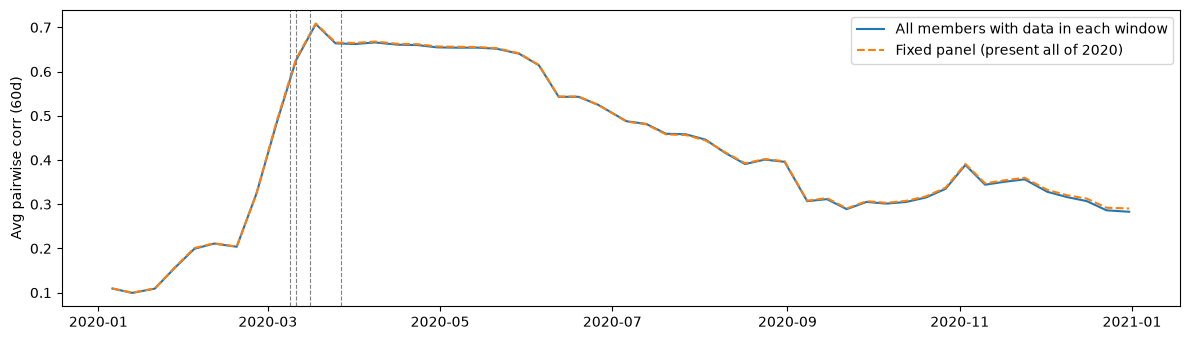

Max absolute difference in avg corr: 0.0074 (window ending 2020-12-31)


C:\Users\dayan\AppData\Local\Temp\ipykernel_32060\587685004.py:14: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  both = conn[["avg_corr"]].join(conn_fixed[["avg_corr"]], rsuffix="_fixed").dropna()


In [14]:
n_days = len(win_mem)
fixed = gap.index[(gap["member_days_in_window"] == n_days) & (gap["priced_days_in_window"] == n_days)]
fixed = fixed.difference(BAD_TICKERS)
print(f"Fixed panel: {len(fixed)} stocks present and priced on all {n_days} trading days of {YEAR}")

conn_fixed = connectedness(rets.loc[WARMUP:END, fixed]).loc[START:END]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(conn.index, conn["avg_corr"], label="All members with data in each window")
ax.plot(conn_fixed.index, conn_fixed["avg_corr"], label=f"Fixed panel (present all of {YEAR})", ls="--")
ax.set_ylabel("Avg pairwise corr (60d)"); ax.legend(); mark_events(ax, labels=False)
plt.tight_layout(); plt.show()

both = conn[["avg_corr"]].join(conn_fixed[["avg_corr"]], rsuffix="_fixed").dropna()
diff = (both["avg_corr"] - both["avg_corr_fixed"]).abs()
print(f"Max absolute difference in avg corr: {diff.max():.4f} (window ending {diff.idxmax().date()})")

## 9. Observations

All numbers are read from the outputs saved in this notebook (run 2026-10-29, with the seven large movers kept in; Section 2b shows `Excluded from stock-level measures: []`). VIX and STLFSI4 are not in this run because `daily_panel.parquet` was not found (Section 3c), so the timing table in Section 7 has four measures.

1. **Data coverage (Section 2):** On average 88.0% of index members had a Yahoo price in 2020 (87.3% over 2020-02-20 to 2020-04-30; lowest 86.7% on 2020-01-02), so the gap is steady rather than crash-specific. 68 of 525 members seen in 2020 have no price at all. Most of the 40 names shown are firms acquired, merged or failed since 2020 (for example ABMD, ALXN, ATVI, CERN, CTXS, FRC), so the panel under-represents firms that left the index (survivorship). Several look like renamed tickers that still need an alias (FB, COG, FLT, FBHS, HFC, LB, NLOK; to verify). AVB, EA, EQR and LEG have only one price row (in 2026) even after `--retry-empty`, so they are a data problem to raise with the team. Only the first 40 of the 68 are shown in the saved output.
2. **Drawdown and volatility (Sections 3 and 3b):** The index peaked at 3,386.15 on 2020-02-19 and bottomed at 2,237.40 on 2020-03-23: a 33.9% fall in 23 trading days. It first closed back at or above the peak on 2020-08-18. The 20-day realized volatility peaked at 97.1% on 2020-03-27 (2019 average 11.3%). Worst day -11.98% (2020-03-16), best +9.38% (2020-03-24). Annualized volatility was 34.4% in 2020 vs 12.5% in 2019 (2.76x). The year still ended +15.3% from the first to the last close (Jan 2 to Dec 31, price only). The weekly first draft below shows a 31.81% fall, smaller than the daily 33.9% because weekly closes miss the daily extremes.
3. **Connectedness (Sections 6 and 7):** Mostly after the peak, not before. Average pairwise correlation was 0.154 from January to mid-February, *below* the 2019 baseline mean of 0.264, then 0.560 in the crash window and 0.626 in April to June, falling to 0.360 in July to December. PC1 share moved the same way (0.228, 0.579, 0.640, 0.401). The peak was 0.707 on 2020-03-18, and the largest single-step rise (+0.157) was in the window ending 2020-03-04. The highest sub-period mean is April to June partly because each 60-day window still contains the March crash.
4. **Timing (Section 7):** Baseline A (2019): realized volatility crossed first (2020-02-25), then dispersion (02-28), and average correlation and PC1 share last (03-04). Baseline B (Jul-Dec 2019) gives the same order, with realized volatility on 02-27. Every first crossing is after the 2020-02-19 market peak (4 to 10 trading days after). The centered episode start (2020-02-14) is before all of them. The trailing start (2020-03-02) is after the volatility and dispersion crossings and before the connectedness crossing (03-04). For a sudden outside shock, no measure here moved before the peak. VIX and STLFSI4 are missing from this run; the team's Week 1 summary reports first crossings on 02-24 and 02-28, which should be confirmed once `daily_panel.parquet` is available.
5. **Cross-section (Section 5):** Five-day average dispersion rose from a 2019 mean of 1.39% to a peak of 6.50% on 2020-03-20. Breadth fell from a 2019 mean of 64.3% to a low of 0.9% on 2020-03-12, so almost every member was below its own 50-day average about a week before the index trough (03-23).
6. **Robustness and sanity checks (Sections 4 and 8):** The equal-weighted portfolio and ^GSPC have a daily-return correlation of 0.954, and 2020 returns of 14.5% vs 15.3%. Two cautions: the Section 4 text expects the equal-weighted line to end *higher*, but it ends lower. The equal-weighted line also includes the Jan 2 return while the index is rebased to the Jan 2 close, so the true gap is roughly 1.5 to 2 points. The fixed panel (430 stocks present and priced on all 253 days) differs from the full panel by at most 0.0073 in average correlation (window ending 2020-12-31), so the connectedness picture is not sensitive to index turnover. That check only uses stocks with prices, so it does not test the bias from the 12% of members we cannot see. Keeping the seven large movers in moved the results only slightly (for example dispersion peak 6.36% to 6.50%, fixed panel 423 to 430 stocks).
7. **Implications for the model:** (a) The 60-day correlation window is the slowest signal: it crossed last (03-04) and peaked 03-18, 3 to 6 trading days after the volatility and dispersion crossings. Try a shorter window (20 days) and daily steps, and compare against the 2022 notebook, where the Week 1 summary says connectedness crossed about three weeks before the first episode. (b) Correlation was below normal before the crash and jumped only once the selloff began, so for a sudden shock treat connectedness as confirmation, not early warning. (c) Salah's centered episode start (2020-02-14) uses future information; for any lead-time test measure from the trailing start (2020-03-02) or from the market peak, and do not expect lead before 2020-02-25. (d) The 2-standard-deviation rule uses overlapping rolling series, so the standard deviation is understated and the thresholds are loose. Week 6 should use a proper lead-time test.


### First draft findings (weekly data, Grace, October 2026)

These came from weekly closes labeled by week **start** date, so dates are approximate and daily extremes are larger. Compare them with Sections 3 and 3b above, then keep or drop them.

* Weekly closing peak 3,380.16 (week of 2020-02-10) to trough 2,304.92 (week of 2020-03-16): a **31.81%** decline. $10,000 at the peak would have fallen to about $6,819.
* First weekly close back above that peak: week of 2020-08-17.
* Worst weekly return **-14.98%** (week of 2020-03-16); best **+12.10%** (week of 2020-04-06).
* Annualized volatility of weekly returns: **10.85%** in 2019 vs **31.73%** in 2020 (2.93x).
* First-to-last weekly close in 2020: **+15.03%** (price index, no dividends). Key lesson from the draft: a positive year can hide a very large interim loss, so returns, drawdowns and volatility have to be read together.

## Save outputs for the team

In [15]:
out = PROC / f"eda_{YEAR}"
out.mkdir(parents=True, exist_ok=True)
conn.to_csv(out / "connectedness_60d.csv")
conn_fixed.to_csv(out / "connectedness_60d_fixed_panel.csv")
cov.to_csv(out / "coverage_by_day.csv")
missing.to_csv(out / "members_missing_prices.csv")
jumps.to_csv(out / "implausible_returns.csv", index=False)
period_stats.to_csv(out / "avg_corr_by_period.csv")
timing.to_csv(out / "timing_table.csv")
print("Saved to", out.relative_to(ROOT))
for f in sorted(out.iterdir()):
    print("  ", f.name)

Saved to data\processed\eda_2020
   avg_corr_by_period.csv
   connectedness_60d.csv
   connectedness_60d_fixed_panel.csv
   coverage_by_day.csv
   implausible_returns.csv
   members_missing_prices.csv
   timing_table.csv
